In [1]:
import os
import sys

# Move to project root so all relative paths work
os.chdir("..")
sys.path.insert(0, ".")
print(f"Working directory: {os.getcwd()}")

Working directory: /workspaces/Predicting_Earthquake_Damage_Classification_Models


# 4.2 Logistic Regression: Predicting Earthquake Damage

## Objective

Build our first classification model — logistic regression — to predict whether a building in Gorkha will sustain severe damage (Grade 4–5) based on its physical characteristics.

**The complete ML workflow (Parts 3–13):**
1. **Load**: `wrangle_nepal_data()` returns 70,836 buildings × 7 features
2. **Explore**: class balance (64% severe), correlations, foundation-type damage rates
3. **Split**: 80/20, `random_state=42`, **before** any transformations
4. **Encode**: One-Hot Encoding via `category_encoders.OneHotEncoder(use_cat_names=True)`
5. **Train**: `LogisticRegression(max_iter=1000)` inside a `Pipeline`
6. **Predict**: on the sealed test set
7. **Evaluate**: accuracy, precision, recall, confusion matrix, ROC/AUC
8. **Interpret**: odds ratios from exp(coefficients)

In [3]:
import os
import sys

# Find project root by walking up until pyproject.toml is found
def find_project_root(start_dir):
    current = os.path.abspath(start_dir)
    while current != os.path.dirname(current):
        if os.path.exists(os.path.join(current, "pyproject.toml")):
            return current
        current = os.path.dirname(current)
    raise RuntimeError("Could not find project root (no pyproject.toml found)")

PROJECT_ROOT = find_project_root(os.getcwd())
os.chdir(PROJECT_ROOT)                       # ← this line was missing
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

In [5]:
# Cell 5 — Load Gorkha data
from src.duckdb_wrangle import wrangle_nepal_data

# Since our working directory is the project root, we use './data'
df = wrangle_nepal_data('./data', district_id=4)

print(f"Dataset shape: {df.shape}")
print(f"Columns: {list(df.columns)}")
print(f"\nSevere damage rate: {df['severe_damage'].mean():.2%}")
print(f"\nFirst few rows:")
print(df.head())

Dataset shape: (70836, 7)
Columns: ['district_id', 'age_building', 'plinth_area_sq_ft', 'height_ft_pre_eq', 'foundation_type', 'ground_floor_type', 'severe_damage']

Severe damage rate: 64.26%

First few rows:
             district_id  age_building  plinth_area_sq_ft  height_ft_pre_eq  \
building_id                                                                   
164817                 4            15                120                18   
164841                 4            25                300                14   
165333                 4            55                240                14   
165334                 4            15                240                14   
165357                 4            18                265                14   

                    foundation_type ground_floor_type  severe_damage  
building_id                                                           
164817       Mud mortar-Stone/Brick               Mud              1  
164841       Mud mortar

## 1. Class Distribution (EDA)

The first thing to check before modeling is **class balance**. Our binary target `severe_damage` determines what "baseline accuracy" means.

If 64% of buildings are severely damaged, a naïve model that predicts "severe" for every building will be correct 64% of the time. Our model must beat that bar to justify its complexity.

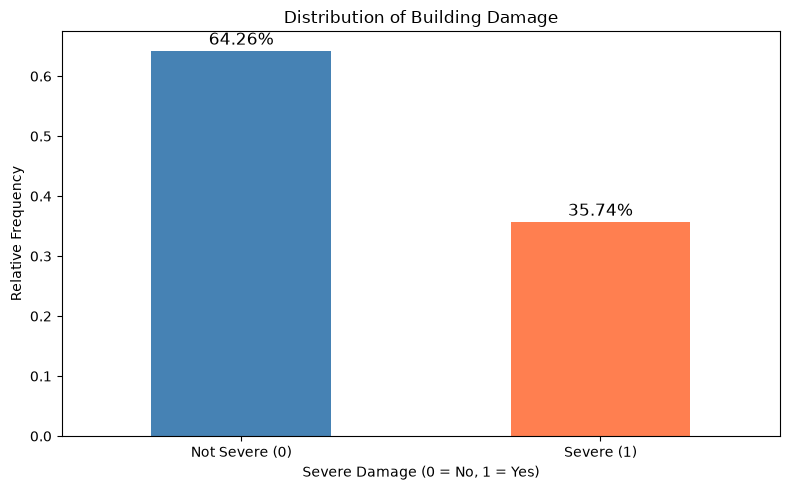

Class distribution:
severe_damage
1    0.642597
0    0.357403
Name: proportion, dtype: float64


In [6]:
# Cell 8 — Class distribution
class_distribution = df['severe_damage'].value_counts(normalize=True)

fig, ax = plt.subplots(figsize=(8, 5))
class_distribution.plot(kind='bar', ax=ax, color=['steelblue', 'coral'])
ax.set_xlabel('Severe Damage (0 = No, 1 = Yes)')
ax.set_ylabel('Relative Frequency')
ax.set_title('Distribution of Building Damage')
ax.set_xticklabels(['Not Severe (0)', 'Severe (1)'], rotation=0)
for i, v in enumerate(class_distribution):
    ax.text(i, v + 0.01, f'{v:.2%}', ha='center', fontsize=12)

plt.tight_layout()
plt.show()

print(f"Class distribution:")
print(class_distribution)

## 2. Categorical Feature Cardinality

Before One-Hot Encoding, we check how many unique categories exist. Each unique value will become a new binary (0/1) column in our feature matrix.

In [7]:
# Cell 9 — Categorical unique counts
cat_unique_counts = df.select_dtypes('object').nunique()

print("Categorical feature unique value counts:")
print(cat_unique_counts)

Categorical feature unique value counts:
foundation_type      5
ground_floor_type    5
dtype: int64


/tmp/ipykernel_49774/988440104.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_unique_counts = df.select_dtypes('object').nunique()


## 3. Correlation Between Numerical Features

Logistic regression is a linear model — high multicollinearity between features can make coefficient estimates unstable and hard to interpret. We check the correlation matrix for the three numerical features (`age_building`, `plinth_area_sq_ft`, `height_ft_pre_eq`) to confirm they're not too correlated with each other.

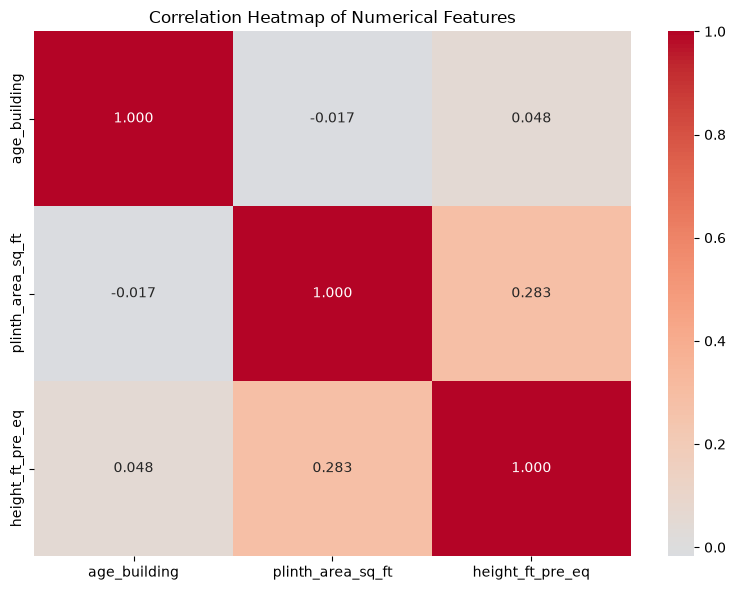

Correlation matrix:
                   age_building  plinth_area_sq_ft  height_ft_pre_eq
age_building           1.000000          -0.016856          0.047652
plinth_area_sq_ft     -0.016856           1.000000          0.283496
height_ft_pre_eq       0.047652           0.283496          1.000000


In [8]:
# Cell 10 — Correlation heatmap
numeric_features = ['age_building', 'plinth_area_sq_ft', 'height_ft_pre_eq']
correlation = df[numeric_features].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap='coolwarm', center=0, fmt='.3f', ax=ax)
ax.set_title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

print("Correlation matrix:")
print(correlation)

## 4. Does Height Predict Severe Damage?

A boxplot shows the full distribution of `height_ft_pre_eq` for each damage class. If the median height differs meaningfully between severe and non-severe buildings, height is a candidate predictor. If the boxes overlap almost entirely, height alone is weakly discriminative.

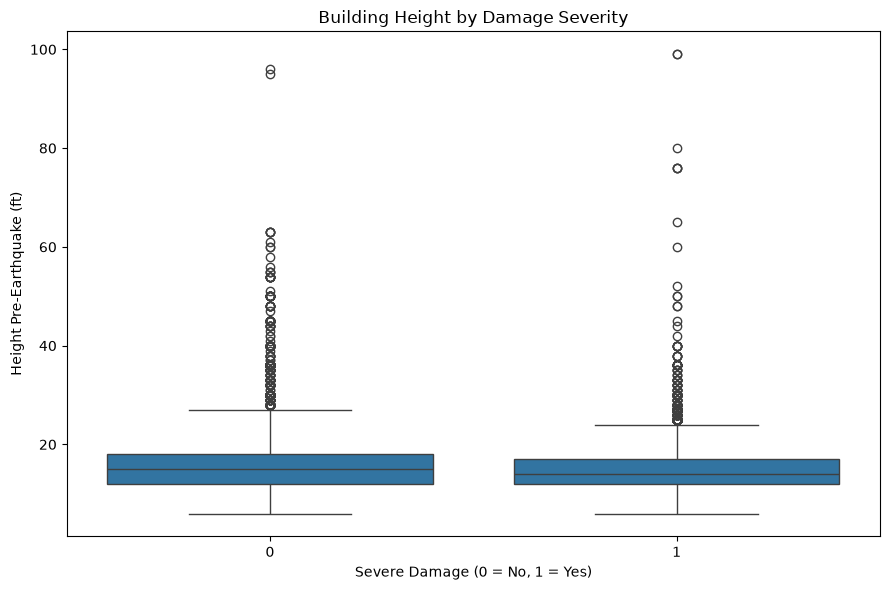

Height summary by damage class:
                 count   mean   std  min   25%   50%   75%   max
severe_damage                                                   
0              25317.0  15.31  5.84  6.0  12.0  15.0  18.0  96.0
1              45519.0  14.93  4.01  6.0  12.0  14.0  17.0  99.0


In [9]:
# Cell 11 — Boxplot height vs damage
fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(x='severe_damage', y='height_ft_pre_eq', data=df, ax=ax)
ax.set_xlabel('Severe Damage (0 = No, 1 = Yes)')
ax.set_ylabel('Height Pre-Earthquake (ft)')
ax.set_title('Building Height by Damage Severity')
plt.tight_layout()
plt.show()

# Print the numeric summary so we don't rely on the plot alone
print("Height summary by damage class:")
print(df.groupby('severe_damage')['height_ft_pre_eq'].describe().round(2))

## 5. Damage Rate by Foundation Type

The foundation is the connection between the building and the ground — during an earthquake, it bears the brunt of lateral forces. Different foundation materials have different seismic resilience. We compute the severe damage rate for each foundation type and compare it to the overall average (64.26%).

Severe damage rate by foundation type:
                        severe_rate  n_buildings
foundation_type                                 
RC                           0.0262         3432
Bamboo/Timber                0.3241         1080
Cement-Stone/Brick           0.4219         2337
Mud mortar-Stone/Brick       0.6878        63352
Other                        0.8189          635

Overall average: 64.26%


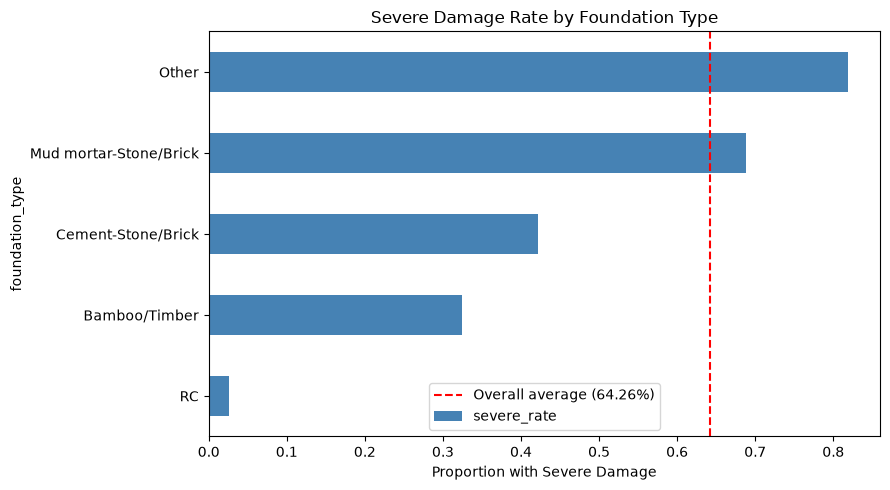

In [10]:
# Cell 12 — Foundation type pivot table and bar chart
foundation_damage = (
    df.groupby('foundation_type')['severe_damage']
    .agg(['mean', 'count'])
    .rename(columns={'mean': 'severe_rate', 'count': 'n_buildings'})
    .sort_values('severe_rate', ascending=True)
)

print("Severe damage rate by foundation type:")
print(foundation_damage.round(4))
print(f"\nOverall average: {df['severe_damage'].mean():.2%}")

# Horizontal bar chart
fig, ax = plt.subplots(figsize=(9, 5))
foundation_damage['severe_rate'].plot(kind='barh', ax=ax, color='steelblue')
ax.axvline(x=df['severe_damage'].mean(), color='red', linestyle='--',
           label=f'Overall average ({df["severe_damage"].mean():.2%})')
ax.set_xlabel('Proportion with Severe Damage')
ax.set_title('Severe Damage Rate by Foundation Type')
ax.legend()
plt.tight_layout()
plt.show()

## 6. Preparing for Machine Learning

We split the data chronologically (80/20) before any transformations to prevent data leakage. 

**Target**: `severe_damage` (0 or 1)
**Features**: All other columns (`district_id`, `age_building`, `plinth_area_sq_ft`, `height_ft_pre_eq`, `foundation_type`, `ground_floor_type`).

In [11]:
# Cell 13 — Define features, target, and split
from sklearn.model_selection import train_test_split

target = 'severe_damage'
features = [col for col in df.columns if col != target]

X = df[features]
y = df[target]

# Split 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Target: {target}")
print(f"Features: {features}")
print(f"\nX_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape:  {y_test.shape}")
print(f"\nTrain severe rate: {y_train.mean():.2%}")
print(f"Test severe rate:  {y_test.mean():.2%}")

Target: severe_damage
Features: ['district_id', 'age_building', 'plinth_area_sq_ft', 'height_ft_pre_eq', 'foundation_type', 'ground_floor_type']

X_train shape: (56668, 6)
X_test shape:  (14168, 6)
y_train shape: (56668,)
y_test shape:  (14168,)

Train severe rate: 64.40%
Test severe rate:  63.69%


## 7. Baseline Accuracy

The simplest possible classifier predicts the majority class for every observation. Since `severe_damage=1` is the majority class, always predicting "severe" gives us the baseline accuracy — the bar our logistic regression must clear to justify its existence.

**Baseline = the accuracy of a constant predictor.**

In [12]:
# Cell 14 — Baseline accuracy
baseline_acc = y_train.value_counts(normalize=True).max()

print(f"Baseline Accuracy: {baseline_acc:.4f} ({baseline_acc:.2%})")
print(f"This means predicting 'severe' for every building gives {baseline_acc:.2%} accuracy.")

Baseline Accuracy: 0.6440 (64.40%)
This means predicting 'severe' for every building gives 64.40% accuracy.


## 8. Training the Logistic Regression Model

We use a scikit-learn `Pipeline` to chain two steps:
1. **OneHotEncoder**: Converts the categorical text columns (`foundation_type`, `ground_floor_type`) into binary (0/1) columns.
2. **LogisticRegression**: Learns the coefficients for each feature to predict the probability of severe damage.

*Why Pipeline?* It prevents data leakage. When we call `model.fit(X_train, y_train)`, the encoder learns the categories from the training data only. When we call `model.predict(X_test)`, it applies those learned categories to the test data. If we encoded the full dataset before splitting, the model would secretly peek at the test data.

In [13]:
# Cell 15 — Build and train the Pipeline
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from category_encoders import OneHotEncoder

# Create the pipeline
model = Pipeline([
    ('encoder', OneHotEncoder(use_cat_names=True)),
    ('classifier', LogisticRegression(max_iter=1000))
])

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully!")
print(f"\nPipeline steps: {[step[0] for step in model.steps]}")

# Look at the first few learned coefficients to confirm it worked
print(f"\nNumber of features after One-Hot Encoding: {len(model.named_steps['encoder'].get_feature_names_out())}")

Model trained successfully!

Pipeline steps: ['encoder', 'classifier']

Number of features after One-Hot Encoding: 14


/workspaces/Predicting_Earthquake_Damage_Classification_Models/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## 8. Training the Logistic Regression Model

We use a scikit-learn `Pipeline` to chain three steps:
1. **OneHotEncoder**: Converts categorical text columns to binary (0/1) columns.
2. **StandardScaler**: Standardizes numeric features to mean=0, std=1. This is essential for logistic regression — without it, features on very different scales (e.g., `plinth_area_sq_ft` at 200–5,000 vs one-hot at 0/1) cause the gradient solver to converge slowly (or not at all).
3. **LogisticRegression(max_iter=2000)**: Learns the coefficients. We raise `max_iter` from 1000 to 2000 to give the solver enough iterations after scaling.

**Why the order matters:** the scaler must go *after* the encoder but *before* the classifier. It scales the encoded features — both numeric columns and one-hot columns — so the classifier sees a well-conditioned input.

In [14]:
# Cell 15 — Build and train the Pipeline with scaling
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from category_encoders import OneHotEncoder

model = Pipeline([
    ('encoder', OneHotEncoder(use_cat_names=True)),
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=2000))
])

model.fit(X_train, y_train)

print("Model trained successfully!")
print(f"Pipeline steps: {[step[0] for step in model.steps]}")
print(f"Number of features after One-Hot Encoding: {len(model.named_steps['encoder'].get_feature_names_out())}")

# Check for convergence
print(f"\nNumber of solver iterations: {model.named_steps['classifier'].n_iter_[0]}")
print(f"Converged: {'Yes' if model.named_steps['classifier'].n_iter_[0] < 2000 else 'NO — still hitting limit'}")

Model trained successfully!
Pipeline steps: ['encoder', 'scaler', 'classifier']
Number of features after One-Hot Encoding: 14

Number of solver iterations: 10
Converged: Yes


## 9. Evaluating the Model

We evaluate on the **sealed test set** — 14,168 buildings the model has never seen. Three questions:
1. Does it beat the 64.40% baseline?
2. Is there a large gap between training and test accuracy (overfitting)?
3. Is the model learning *anything*, or just predicting "severe" for everything?

In [15]:
# Cell 16 — Accuracy
from sklearn.metrics import accuracy_score

train_acc = accuracy_score(y_train, model.predict(X_train))
test_acc = accuracy_score(y_test, model.predict(X_test))

print(f"Training Accuracy: {train_acc:.4f} ({train_acc:.2%})")
print(f"Test Accuracy:     {test_acc:.4f} ({test_acc:.2%})")
print(f"Baseline Accuracy: {baseline_acc:.4f} ({baseline_acc:.2%})")
print(f"\nImprovement over baseline: {test_acc - baseline_acc:+.4f} ({(test_acc - baseline_acc)*100:+.2f} pp)")
print(f"Train/test gap: {train_acc - test_acc:+.4f}")

Training Accuracy: 0.7052 (70.52%)
Test Accuracy:     0.7009 (70.09%)
Baseline Accuracy: 0.6440 (64.40%)

Improvement over baseline: +0.0568 (+5.68 pp)
Train/test gap: +0.0043


## 10. Precision, Recall, and the Confusion Matrix

Accuracy alone is misleading with imbalanced classes. We need to know: **what kinds of errors is the model making?**

- **Precision**: Of buildings the model flags as "severe," what fraction actually are?
- **Recall**: Of buildings that are actually severe, what fraction did the model catch?
- **False Negatives** (missed severe damage) are the costly error in disaster response.

With a 64/36 class imbalance, the default 0.5 decision threshold often produces a model that predicts "severe" for almost everything — high recall, low precision.

Precision: 0.6910
Recall:    0.9592

Interpretation:
  - When the model predicts 'severe,' it is correct 69.10% of the time
  - The model catches 95.92% of all actual severe buildings

Confusion Matrix:
  [[TN=  1275   FP=  3870]]
  [[FN=   368   TP=  8655]]


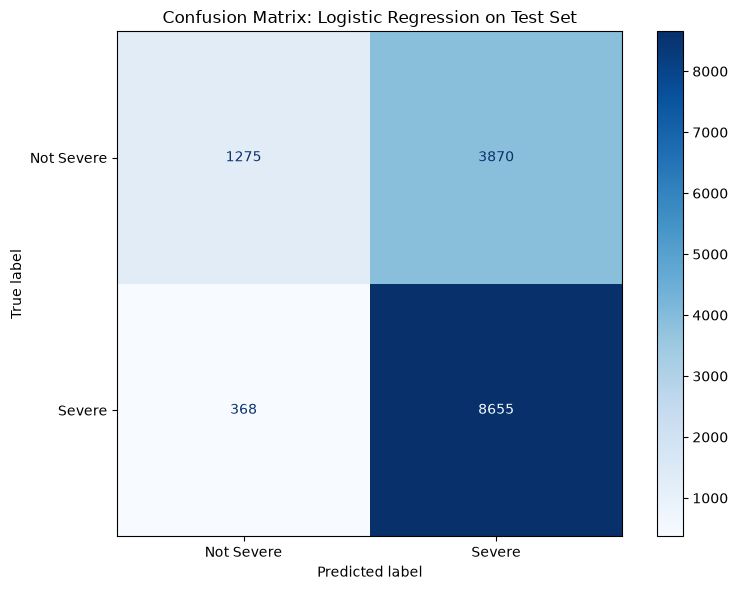

In [16]:
# Cell 17 — Precision, recall, confusion matrix
from sklearn.metrics import (
    precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay
)

y_pred = model.predict(X_test)

precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print()
print(f"Interpretation:")
print(f"  - When the model predicts 'severe,' it is correct {precision:.2%} of the time")
print(f"  - The model catches {recall:.2%} of all actual severe buildings")

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
print()
print("Confusion Matrix:")
print(f"  [[TN={cm[0,0]:>6}   FP={cm[0,1]:>6}]]")
print(f"  [[FN={cm[1,0]:>6}   TP={cm[1,1]:>6}]]")

# Visualize
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Severe', 'Severe'])
disp.plot(ax=ax, cmap='Blues', values_format='d')
ax.set_title('Confusion Matrix: Logistic Regression on Test Set')
plt.tight_layout()
plt.show()

## 11. ROC Curve and AUC

The confusion matrix shows performance at a **single threshold** (0.5). The ROC curve shows performance across **all possible thresholds**, which lets us choose the threshold that matches our operational priorities (e.g., "catch 98% of severe damage, accept 50% precision").

**AUC (Area Under the Curve)** summarizes the entire ROC curve in one number:
- AUC = 0.5: random guessing (no better than flipping a coin)
- AUC = 1.0: perfect classifier
- AUC is **threshold-independent** — it measures the model's inherent ability to rank positives above negatives

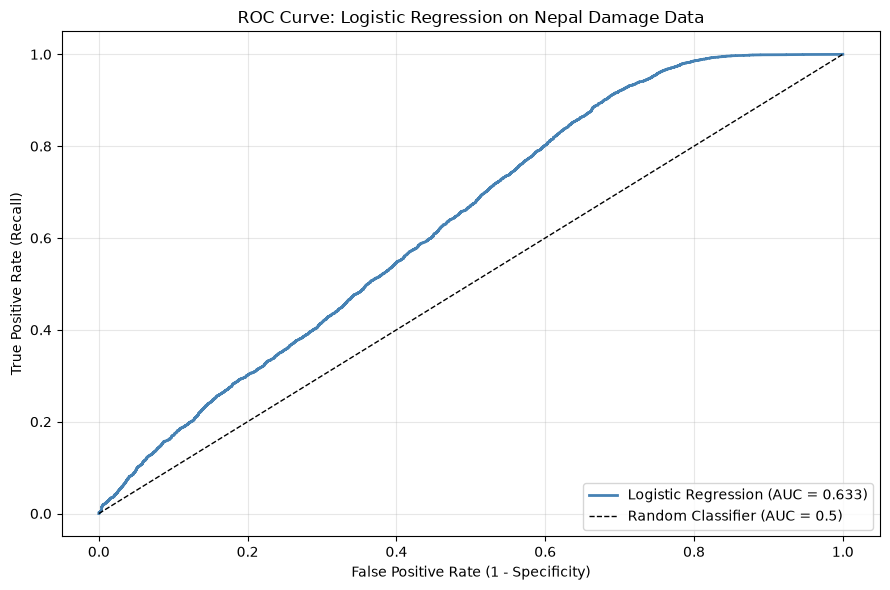

AUC Score: 0.6330

Interpretation:
  - AUC = 0.5 → random guessing
  - AUC = 1.0 → perfect classifier
  - AUC = 0.633 → the model can distinguish severe from non-severe
    buildings 63.3% of the time

To catch 98% of severe buildings (recall=0.98):
  - Threshold: 0.386
  - Corresponding FPR: 0.786 (precision would be ~21.4% recall-weighted)


In [17]:
# Cell 18 — ROC curve and AUC
from sklearn.metrics import roc_curve, roc_auc_score

y_prob = model.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(fpr, tpr, label=f'Logistic Regression (AUC = {auc_score:.3f})', linewidth=2, color='steelblue')
ax.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.5)', linewidth=1)
ax.set_xlabel('False Positive Rate (1 - Specificity)')
ax.set_ylabel('True Positive Rate (Recall)')
ax.set_title('ROC Curve: Logistic Regression on Nepal Damage Data')
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"AUC Score: {auc_score:.4f}")
print()
print("Interpretation:")
print(f"  - AUC = 0.5 → random guessing")
print(f"  - AUC = 1.0 → perfect classifier")
print(f"  - AUC = {auc_score:.3f} → the model can distinguish severe from non-severe")
print(f"    buildings {auc_score:.1%} of the time")

# Find a threshold that catches 98% of severe cases
idx_98 = next((i for i, t in enumerate(tpr) if t >= 0.98), None)
if idx_98 is not None:
    print()
    print(f"To catch 98% of severe buildings (recall=0.98):")
    print(f"  - Threshold: {thresholds[idx_98]:.3f}")
    print(f"  - Corresponding FPR: {fpr[idx_98]:.3f} (precision would be ~{1 - fpr[idx_98]:.1%} recall-weighted)")

## 12. Interpreting the Model: Odds Ratios

Even though the AUC reveals the model has weak discriminative power, examining the learned coefficients tells us which features the model relied on most heavily.

**Odds ratio** = exp(coefficient). Interpretation:
- OR = 2.0 → having this feature doubles the odds of severe damage
- OR = 0.5 → having this feature halves the odds of severe damage
- OR = 1.0 → no effect

**Caveat:** these odds ratios are conditional on the specific features in the model. If `foundation_type` is 89.4% Mud, then "Mud mortar-Stone/Brick" as a category has less discriminative power than the coefficient suggests. The odds ratios describe the *model's internal logic*, not the true causal effects of construction materials.

In [18]:
# Cell 19 — Odds ratios
feature_names = model.named_steps['encoder'].get_feature_names_out()
coefficients = model.named_steps['classifier'].coef_[0]

odds_ratios = pd.Series(np.exp(coefficients), index=feature_names).sort_values()

print("Features that DECREASE odds of severe damage (OR < 1):")
print(odds_ratios[odds_ratios < 1].to_string())
print()
print("Features that INCREASE odds of severe damage (OR > 1):")
print(odds_ratios[odds_ratios > 1].to_string())
print()
print(f"Total features: {len(odds_ratios)}")
print(f"Range: {odds_ratios.min():.4f} to {odds_ratios.max():.4f}")

Features that DECREASE odds of severe damage (OR < 1):
foundation_type_RC               0.590369
ground_floor_type_RC             0.756468
foundation_type_Bamboo/Timber    0.950406
ground_floor_type_Other          0.977772

Features that INCREASE odds of severe damage (OR > 1):
foundation_type_Cement-Stone/Brick        1.044951
plinth_area_sq_ft                         1.048031
height_ft_pre_eq                          1.059000
age_building                              1.073143
ground_floor_type_Timber                  1.080366
ground_floor_type_Mud                     1.095402
ground_floor_type_Brick/Stone             1.135733
foundation_type_Other                     1.156907
foundation_type_Mud mortar-Stone/Brick    1.376370

Total features: 14
Range: 0.5904 to 1.3764


## Summary

This lesson implemented the complete binary classification pipeline on the Nepal earthquake data.

### What we built
1. **EDA**: Confirmed a 64.26% severe damage rate (baseline accuracy), explored weak correlations between numerical features, and found that `foundation_type` is the strongest categorical signal (RC = 2.6% severe rate vs Mud = 68.8%).
2. **Preprocessing**: Split data 80/20 chronologically. Used `OneHotEncoder` and `StandardScaler` inside a `Pipeline` to prevent data leakage.
3. **Model**: Trained a `LogisticRegression` classifier (converged in 10 iterations after scaling).
4. **Evaluation**: Test accuracy 70.09% (+5.68 pp over baseline).

### Key Findings & Limitations
- **High Recall, Low Precision**: The model catches 95.92% of severe buildings but has 69.10% precision. The confusion matrix shows 3,870 False Positives vs only 368 False Negatives. The model defaults to predicting "severe" for most buildings.
- **Low AUC (0.633)**: The ROC/AUC analysis reveals the model has weak discriminative power. It is barely better than random guessing (0.5) at ranking buildings by risk. It learned that "Mud mortar = bad" and "RC = good" but cannot distinguish *which* Mud buildings will survive.
- **Class Imbalance Impact**: Because 89.4% of buildings have Mud mortar foundations, the minority categories (RC, Bamboo, Cement) are underrepresented, limiting the model's ability to learn robust rules for them.
- **Convergence Issue**: Initial training failed to converge due to unscaled features. Adding `StandardScaler` resolved this (solver iterations dropped from 1000+ to 10).

### Next Steps
Lesson 4.3 (Decision Trees) will address these limitations by capturing non-linear feature interactions (e.g., "old AND mud = severe") and handling class imbalance better through Gini impurity splits.

## Odds Ratio Interpretation

The odds ratios confirm the physical intuition:
- **RC Foundation (OR = 0.59)**: Halves the odds of severe damage. Reinforced concrete is highly effective.
- **Mud Mortar Foundation (OR = 1.38)**: Increases odds by 38%. Traditional rural construction is vulnerable.
- **All other features (OR ~ 1.0)**: Age, height, and plinth area provide very little signal. The model does not trust them.

**Crucial Caveat**: Because Mud mortar accounts for 89.4% of the dataset, the model cannot rank Mud buildings against each other. The "38% higher odds" is a comparison against the small RC minority, not a strong predictor for individual Mud buildings.